# **Penting**
- Jangan mengubah atau menambahkan cell text yang sudah disediakan, Anda hanya perlu mengerjakan cell code yang sudah disediakan.
- Pastikan seluruh kriteria memiliki output yang sesuai, karena jika tidak ada output dianggap tidak selesai.
- Misal, Anda menggunakan df = df.dropna() silakan gunakan df.isnull().sum() sebagai tanda sudah berhasil. Silakan sesuaikan seluruh output dengan perintah yang sudah disediakan.
- Pastikan Anda melakukan Run All sebelum mengirimkan submission untuk memastikan seluruh cell berjalan dengan baik.
- Pastikan Anda menggunakan variabel df dari awal sampai akhir dan tidak diperbolehkan mengganti nama variabel tersebut.
- Hapus simbol pagar (#) pada kode yang bertipe komentar jika Anda menerapkan kriteria tambahan
- Biarkan simbol pagar (#) jika Anda tidak menerapkan kriteria tambahan
- Pastikan Anda mengerjakan sesuai section yang sudah diberikan tanpa mengubah judul atau header yang disediakan.

# **INFORMASI DATASET**

Dataset ini menyajikan gambaran mendalam mengenai perilaku transaksi dan pola aktivitas keuangan, sehingga sangat ideal untuk eksplorasi **deteksi penipuan (fraud detection)** dan **identifikasi anomali**. Dataset ini mencakup **2.512 sampel data transaksi**, yang mencakup berbagai atribut transaksi, demografi nasabah, dan pola penggunaan.

Setiap entri memberikan wawasan komprehensif terhadap perilaku transaksi, memungkinkan analisis untuk **keamanan finansial** dan pengembangan model prediktif.

## Fitur Utama

- **`TransactionID`**: Pengidentifikasi unik alfanumerik untuk setiap transaksi.  
- **`AccountID`**: ID unik untuk setiap akun, dapat memiliki banyak transaksi.  
- **`TransactionAmount`**: Nilai transaksi dalam mata uang, mulai dari pengeluaran kecil hingga pembelian besar.  
- **`TransactionDate`**: Tanggal dan waktu transaksi terjadi.  
- **`TransactionType`**: Tipe transaksi berupa `'Credit'` atau `'Debit'`.  
- **`Location`**: Lokasi geografis transaksi (nama kota di Amerika Serikat).  
- **`DeviceID`**: ID perangkat yang digunakan dalam transaksi.  
- **`IP Address`**: Alamat IPv4 yang digunakan saat transaksi, dapat berubah untuk beberapa akun.  
- **`MerchantID`**: ID unik merchant, menunjukkan merchant utama dan anomali transaksi.  
- **`AccountBalance`**: Saldo akun setelah transaksi berlangsung.  
- **`PreviousTransactionDate`**: Tanggal transaksi terakhir pada akun, berguna untuk menghitung frekuensi transaksi.  
- **`Channel`**: Kanal transaksi seperti `Online`, `ATM`, atau `Branch`.  
- **`CustomerAge`**: Usia pemilik akun.  
- **`CustomerOccupation`**: Profesi pengguna seperti `Dokter`, `Insinyur`, `Mahasiswa`, atau `Pensiunan`.  
- **`TransactionDuration`**: Lama waktu transaksi (dalam detik).  
- **`LoginAttempts`**: Jumlah upaya login sebelum transaksi—jumlah tinggi bisa mengindikasikan anomali.

Tugas kamu adalah membuat model clustering yang selanjutnya akan digunakan untuk membuat model klasifikasi.


# **1. Import Library**
Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning. Semua library yang dibutuhkan harus **import** di **cell** ini, jika ada library yang dijalankan di cell lain maka **submission langsung ditolak**

In [ ]:
#Type your code here
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer

# **2. Memuat Dataset**
Pada tahap ini, Anda perlu memuat dataset ke dalam notebook lalu mengecek informasi dataset sebelum nantinya dilakukan pembersihan. Hal-hal yang perlu dilakukan pada tahapan ini yaitu:
1. **Memahami Struktur Data**
   - Dataset harus mengambil referensi wajib digunakan (bisa dilihat [Disini](https://drive.google.com/drive/folders/1Zs7VmPZ-jNwsRlMKH65Ea-LApSwx6lKx?usp=drive_link))
   - Melakukan loading dataset ke dalam notebook dan menampilkan 5 baris pertama dengan function `head`.
   - Tinjau jumlah baris kolom dan jenis data dalam dataset dengan function `info`.  
   - Menampilkan statistik deskriptif dataset dengan menjalankan `describe`.
   - Pastikan **setiap function tersebut** memiliki **output pada setiap cell** code. Jika tidak **submission langsung ditolak**
   

Gunakan code ini untuk melakukan load data secara otomatis tanpa harus download data tersebut secara manual:
```python
url='https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?gid=2020477971&single=true&output=csv'
df = pd.read_csv(url)
```

Penting: pada kriteria pertama hindari penggunaan print() dan display() karena seluruh fungsi yang digunakan sudah memiliki standar output dan menghasilkan output yang diharapkan.

Kriteria 1 akan ditolak ketika:
- print(__.head())
- display(___.head())
dst

Kriteria 1 akan diterima ketika Anda menggunakan fungsi yang diminta tanpa menambahkan deskripsi apapun.

In [ ]:
# Load data
url='https://docs.google.com/spreadsheets/d/e/2PACX-1vTbg5WVW6W3c8SPNUGc3A3AL-AG32TPEQGpdzARfNICMsLFI0LQj0jporhsLCeVhkN5AoRsTkn08AYl/pub?gid=2020477971&single=true&output=csv'
df = pd.read_csv(url)

In [ ]:
# Tampilkan 5 baris pertama dengan function head.
df.head()

,TransactionID,AccountID,TransactionAmount,PreviousTransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 8:08:08
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 8:09:35
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 8:07:04
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 8:09:06
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,198.0,1.0,7429.40,2024-11-04 8:06:39


In [ ]:
# Tinjau jumlah baris kolom dan jenis data dalam dataset dengan info.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2537 entries, 0 to 2536
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   TransactionID            2508 non-null   object 
 1   AccountID                2516 non-null   object 
 2   TransactionAmount        2511 non-null   float64
 3   PreviousTransactionDate  2509 non-null   object 
 4   TransactionType          2507 non-null   object 
 5   Location                 2507 non-null   object 
 6   DeviceID                 2507 non-null   object 
 7   IP Address               2517 non-null   object 
 8   MerchantID               2514 non-null   object 
 9   Channel                  2510 non-null   object 
 10  CustomerAge              2519 non-null   float64
 11  CustomerOccupation       2514 non-null   object 
 12  TransactionDuration      2511 non-null   float64
 13  LoginAttempts            2516 non-null   float64
 14  AccountBalance          

In [ ]:
# Menampilkan statistik deskriptif dataset dengan menjalankan describe
df.describe()

,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance
count,2511.000000,2519.000000,2511.000000,2516.000000,2510.000000
mean,297.656468,44.678444,119.422939,1.121622,5113.438124
std,292.230367,17.837359,70.078513,0.594469,3897.975861
min,0.260000,18.000000,10.000000,1.000000,101.250000
25%,81.310000,27.000000,63.000000,1.000000,1504.727500
50%,211.360000,45.000000,112.000000,1.000000,4734.110000
75%,413.105000,59.000000,161.000000,1.000000,7672.687500
max,1919.110000,80.000000,300.000000,5.000000,14977.990000


(Opsional) Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA) [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

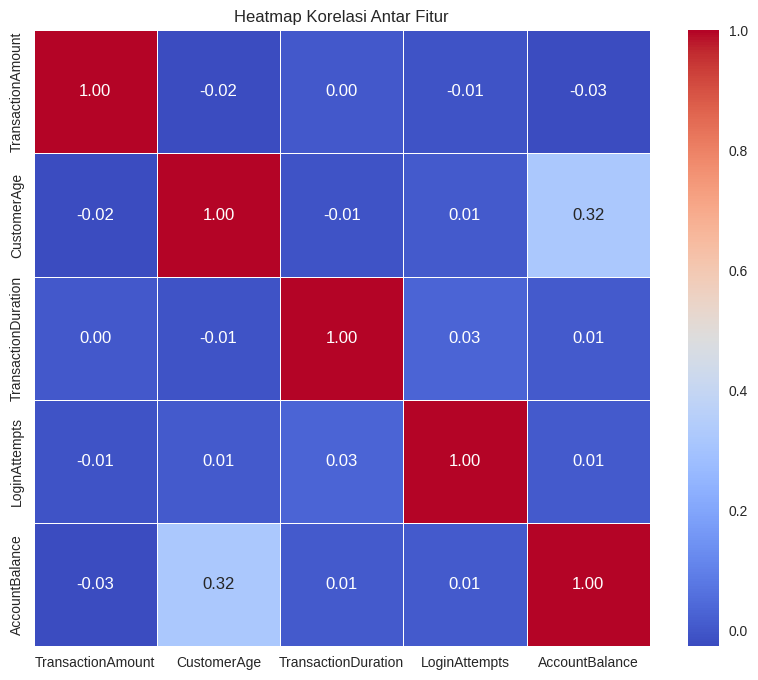

In [ ]:
# Menampilkan korelasi antar fitur (Opsional Skilled 1)
numeric_df=df.select_dtypes(include='number')
corr_matrix=numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            fmt=".2f",
            linewidths=0.5,
            square=True)
plt.title("Heatmap Korelasi Antar Fitur")
plt.show()


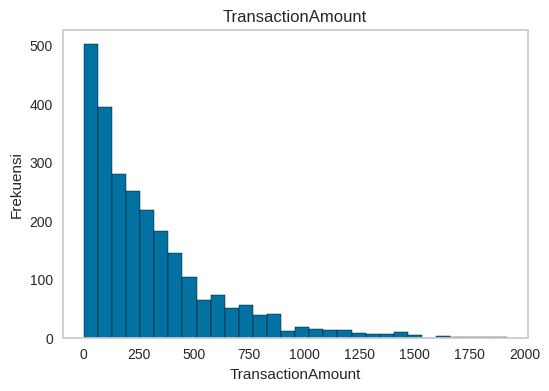

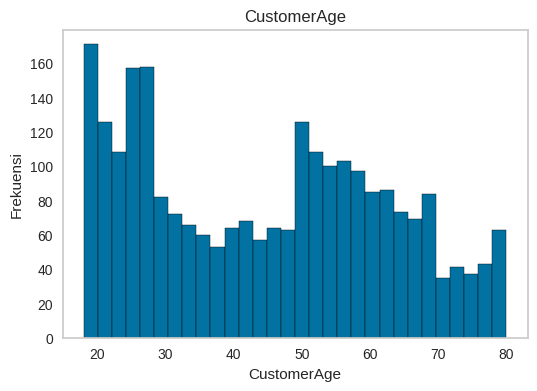

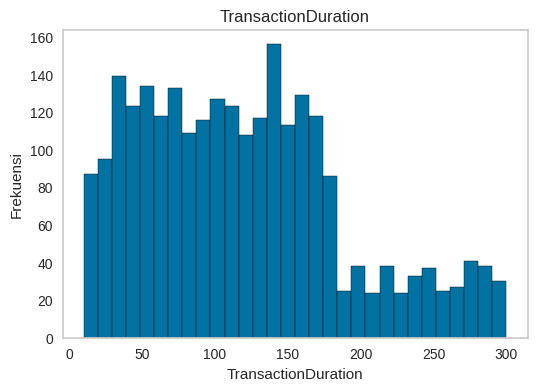

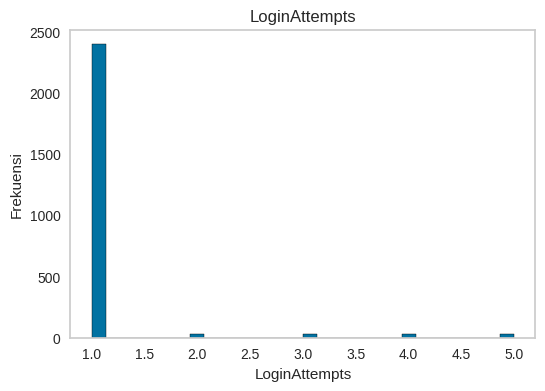

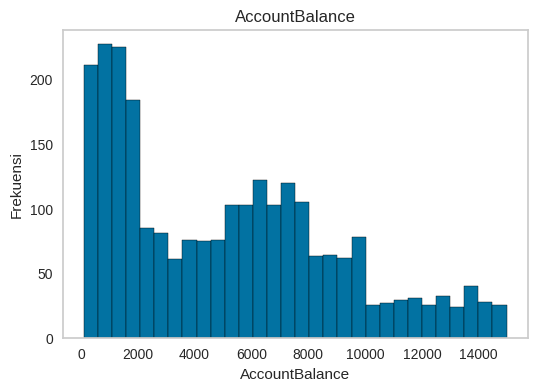

In [ ]:
# Menampilkan histogram untuk semua kolom numerik (Opsional Skilled 1)

for num in numeric_df:
  plt.figure(figsize=(6,4))
  df[num].hist(bins=30,edgecolor='black')
  plt.title(num)
  plt.xlabel(num)
  plt.ylabel('Frekuensi')
  plt.grid(False)
  plt.show()

(Opsional) Memuat Dataset dan Melakukan Exploratory Data Analysis (EDA) [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

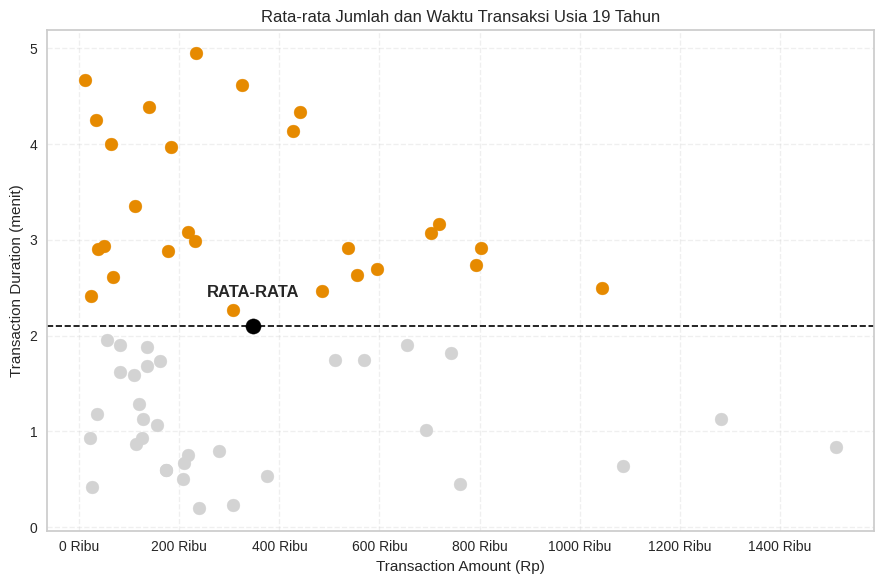

In [ ]:
# Visualisasi yang lebih informatif (Opsional Advanced 1)

mask_age = (df['CustomerAge'] == 19)
sub = df.loc[mask_age].copy()

sub['DurasiMenit'] = sub['TransactionDuration'] / 60

# Hitung rata-rata durasi
mean_dur = sub['DurasiMenit'].mean()

# Tandai warna titik
sub['AboveMean'] = sub['DurasiMenit'] > mean_dur

# Plot
plt.figure(figsize=(9, 6))
plt.title("Rata-rata Jumlah dan Waktu Transaksi Usia 19 Tahun")

# Titik di atas rata-rata
plt.scatter(sub.loc[sub['AboveMean'], 'TransactionAmount'],
            sub.loc[sub['AboveMean'], 'DurasiMenit'],
            color='#E68A00', s=85)

# Titik di bawah rata-rata
plt.scatter(sub.loc[~sub['AboveMean'], 'TransactionAmount'],
            sub.loc[~sub['AboveMean'], 'DurasiMenit'],
            color='lightgray', s=85)

# Garis rata-rata + titik penanda
plt.axhline(mean_dur, color='black', linestyle='--', linewidth=1.2)
plt.scatter(sub['TransactionAmount'].mean(), mean_dur,
            color='black', s=120, zorder=5)
plt.text(sub['TransactionAmount'].mean(), mean_dur + 0.3,
         'RATA-RATA', weight='bold', ha='center')

plt.xlabel('Transaction Amount (Rp)')
plt.ylabel('Transaction Duration (menit)')

# Format Rupiah di sumbu-X
plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'{x:.0f} Ribu'))

# Format menit di sumbu-Y
plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f'{y:.0f}'))

plt.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()


# **3. Pembersihan dan Pra Pemrosesan Data**

Pada tahap ini, Anda akan melakukan **Pembersihan Dataset** untuk menjadikan dataset mudah diintepretasi dan bisa dilatih. Hal-hal yang wajib kamu lakukan yaitu:

1. **Mengecek dataset** menggunakan isnull().sum() dan duplicated().sum().
2. Melakukan feature scaling menggunakan `MinMaxScaler()` atau `StandardScalar()` untuk fitur numerik.
3. Melakukan feature encoding menggunakan `LabelEncoder()` untuk fitur kategorikal.
4. Melakukan drop pada kolom id.
5. **Ketentuan Cell Code**
   - Pastikan **setiap pemeriksaan tersebut** memiliki **output pada cell-nya**. Jika tidak **submission langsung ditolak**


In [ ]:
# Mengecek dataset menggunakan isnull().sum()
df.isnull().sum()

,0
TransactionID,29
AccountID,21
TransactionAmount,26
PreviousTransactionDate,28
TransactionType,30
Location,30
DeviceID,30
IP Address,20
MerchantID,23
Channel,27


In [ ]:
# Mengecek dataset menggunakan duplicated().sum()
df.duplicated().sum()

np.int64(21)

In [ ]:
# Melakukan feature scaling menggunakan MinMaxScaler() atau StandardScalar() untuk fitur numerik.
# Pastikan kamu menggunakan function head setelah melalukan scaling.
numeric_cols=['TransactionAmount','TransactionDuration','LoginAttempts','AccountBalance','CustomerAge']
scaler=MinMaxScaler()
df[numeric_cols]=scaler.fit_transform(df[numeric_cols])
df.head()

,TransactionID,AccountID,TransactionAmount,PreviousTransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,TX000001,AC00128,0.007207,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 8:08:08
1,TX000002,AC00455,0.195940,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 8:09:35
2,TX000003,AC00019,0.065680,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 8:07:04
3,TX000004,AC00070,0.096016,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 8:09:06
4,TX000005,AC00411,0.006874,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,NaN,Student,0.648276,0.0,0.492591,2024-11-04 8:06:39


In [ ]:
# Melakukan drop pada kolom yang memiliki keterangan id dan IP Address
df_cleaned=df.drop(columns=['TransactionID','AccountID','DeviceID','IP Address','MerchantID'])
df_cleaned.head()

,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate
0,0.007207,2023-04-11 16:29:14,Debit,San Diego,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 8:08:08
1,0.195940,2023-06-27 16:44:19,Debit,Houston,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 8:09:35
2,0.065680,2023-07-10 18:16:08,Debit,Mesa,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 8:07:04
3,0.096016,2023-05-05 16:32:11,Debit,Raleigh,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 8:09:06
4,0.006874,2023-10-16 17:51:24,Credit,Atlanta,Online,NaN,Student,0.648276,0.0,0.492591,2024-11-04 8:06:39


In [ ]:
# Melakukan feature encoding menggunakan LabelEncoder() untuk fitur kategorikal.
# Pastikan kamu menggunakan function head setelah melalukan encoding.

cat_cols=["TransactionType","Channel","CustomerOccupation","Location"]
encoders={}
for col in cat_cols:
  le=LabelEncoder()
  df_cleaned[col+"_enc"]=le.fit_transform(df_cleaned[col].astype(str))
  encoders[col]=le

df_cleaned

,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc
0,0.007207,2023-04-11 16:29:14,Debit,San Diego,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 8:08:08,1,0,0,36
1,0.195940,2023-06-27 16:44:19,Debit,Houston,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 8:09:35,1,0,0,15
2,0.065680,2023-07-10 18:16:08,Debit,Mesa,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 8:07:04,1,2,3,23
3,0.096016,2023-05-05 16:32:11,Debit,Raleigh,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 8:09:06,1,2,3,33
4,0.006874,2023-10-16 17:51:24,Credit,Atlanta,Online,NaN,Student,0.648276,0.0,0.492591,2024-11-04 8:06:39,0,2,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2532,0.119770,2023-05-01 16:23:40,Debit,Austin,Online,0.983871,Retired,0.393103,0.0,0.293401,2024-11-04 8:11:47,1,2,2,2
2533,0.292529,2023-06-23 17:38:26,Debit,Sacramento,Online,0.758065,Doctor,0.044828,0.0,0.782941,2024-11-04 8:06:32,1,2,0,34
2534,0.256847,2023-07-31 16:25:26,Debit,Colorado Springs,Branch,0.564516,Retired,0.779310,0.0,0.492832,2024-11-04 8:08:01,1,1,2,7
2535,0.103374,2023-05-15 16:19:14,Credit,Tucson,Branch,0.145161,Student,0.255172,0.0,0.073593,2024-11-04 8:06:38,0,1,3,40


In [ ]:
# Last checking gunakan columns.tolist() untuk checking seluruh fitur yang ada.
# Perbaiki kode di bawah ini tanpa menambahkan atau mengurangi cell code ini.
df_cleaned.columns.tolist()

['TransactionAmount',
 'PreviousTransactionDate',
 'TransactionType',
 'Location',
 'Channel',
 'CustomerAge',
 'CustomerOccupation',
 'TransactionDuration',
 'LoginAttempts',
 'AccountBalance',
 'TransactionDate',
 'TransactionType_enc',
 'Channel_enc',
 'CustomerOccupation_enc',
 'Location_enc']

(Opsional) Pembersihan dan Pra Pemrosesan Data [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [ ]:
# Menangani data yang hilang (bisa menggunakan dropna() atau metode imputasi fillna()).
df_cleaned=df_cleaned.dropna()
df_cleaned

,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc
0,0.007207,2023-04-11 16:29:14,Debit,San Diego,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 8:08:08,1,0,0,36
1,0.195940,2023-06-27 16:44:19,Debit,Houston,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 8:09:35,1,0,0,15
2,0.065680,2023-07-10 18:16:08,Debit,Mesa,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 8:07:04,1,2,3,23
3,0.096016,2023-05-05 16:32:11,Debit,Raleigh,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 8:09:06,1,2,3,33
5,0.047888,2023-04-03 17:15:01,Debit,Oklahoma City,ATM,0.000000,Student,0.558621,0.0,0.045738,2024-11-04 8:06:36,1,0,3,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2532,0.119770,2023-05-01 16:23:40,Debit,Austin,Online,0.983871,Retired,0.393103,0.0,0.293401,2024-11-04 8:11:47,1,2,2,2
2533,0.292529,2023-06-23 17:38:26,Debit,Sacramento,Online,0.758065,Doctor,0.044828,0.0,0.782941,2024-11-04 8:06:32,1,2,0,34
2534,0.256847,2023-07-31 16:25:26,Debit,Colorado Springs,Branch,0.564516,Retired,0.779310,0.0,0.492832,2024-11-04 8:08:01,1,1,2,7
2535,0.103374,2023-05-15 16:19:14,Credit,Tucson,Branch,0.145161,Student,0.255172,0.0,0.073593,2024-11-04 8:06:38,0,1,3,40


In [ ]:
# Menghapus data duplikat menggunakan drop_duplicates().
df_cleaned=df_cleaned.drop_duplicates()
df_cleaned

,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc
0,0.007207,2023-04-11 16:29:14,Debit,San Diego,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 8:08:08,1,0,0,36
1,0.195940,2023-06-27 16:44:19,Debit,Houston,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 8:09:35,1,0,0,15
2,0.065680,2023-07-10 18:16:08,Debit,Mesa,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 8:07:04,1,2,3,23
3,0.096016,2023-05-05 16:32:11,Debit,Raleigh,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 8:09:06,1,2,3,33
5,0.047888,2023-04-03 17:15:01,Debit,Oklahoma City,ATM,0.000000,Student,0.558621,0.0,0.045738,2024-11-04 8:06:36,1,0,3,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2510,0.096782,2023-02-24 16:24:46,Debit,Denver,Online,0.080645,Student,0.031034,0.0,0.112636,2024-11-04 8:12:22,1,2,3,10
2511,0.126545,2023-02-14 16:21:23,Credit,Jacksonville,Online,0.096774,Student,0.286207,0.0,0.002017,2024-11-04 8:07:49,0,2,3,17
2523,0.006212,2023-04-20 18:50:39,Debit,New York,Branch,0.935484,Retired,0.231034,0.0,0.323188,2024-11-04 8:07:37,1,1,2,27
2524,0.120833,2023-12-28 17:31:03,Debit,Omaha,ATM,0.306452,Engineer,0.141379,0.0,0.442881,2024-11-04 8:09:17,1,0,1,29


(Opsional) Pembersihan dan Pra Pemrosesan Data [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

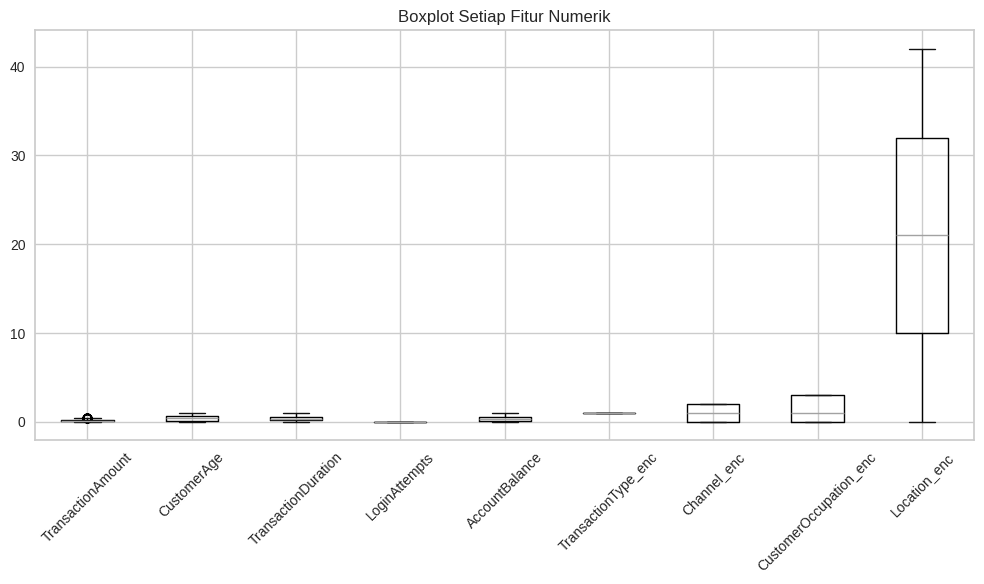

In [ ]:
# Melakukan Handling Outlier Data berdasarkan jumlah outlier, apakah menggunakan metode drop atau mengisi nilai tersebut.
def drop_outliers(df_cleaned,factor=1.5,cols=None, reset_index=True):
  num_cols=cols if cols is not None else df_cleaned.select_dtypes(include='number').columns
  Q1=df_cleaned[num_cols].quantile(0.25)
  Q3=df_cleaned[num_cols].quantile(0.75)
  IQR=Q3-Q1
  lower=Q1-factor*IQR
  upper=Q3+factor*IQR
  outlier_mask=(df_cleaned[num_cols]<lower)|(df_cleaned[num_cols]>upper)
  df_cleaned=df_cleaned[~outlier_mask.any(axis=1)]
  if reset_index:
    df_cleaned=df_cleaned.reset_index(drop=True)
  return df_cleaned

df_cleaned=drop_outliers(df_cleaned)
df_cleaned

df_cleaned.select_dtypes(include='number').boxplot(figsize=(10, 6))
plt.title("Boxplot Setiap Fitur Numerik")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Melakukan binning data berdasarkan kondisi rentang nilai pada fitur numerik,
# lakukan pada satu sampai dua fitur numerik.
# Silahkan lakukan encode hasil binning tersebut menggunakan LabelEncoder.
# Pastikan kamu mengerjakan tahapan ini pada satu cell.
bin_cols=['CustomerAge','LoginAttempts']
bin_params={
    'CustomerAge':{
        'bins': [-0.001,0.3999,0.66,1.001],
        'labels':['Young','Medium','Old']
    },
    'LoginAttempts':{
        'bins':[-0.001,0.4999,1.001],
        'labels':['Low','High']
    }
}

encoders2={}

for col in bin_cols:
  bin_col=col+'_bin'
  enc_col=col+'_bin_enc'
  df_cleaned[bin_col]=pd.cut(
      df_cleaned[col],
      bins=bin_params[col]['bins'],
      labels=bin_params[col]['labels']
  )

  le=LabelEncoder()
  df_cleaned[enc_col]=le.fit_transform(df_cleaned[bin_col])
  encoders2[bin_col]=le

print(df_cleaned[[*bin_cols, *(c + '_bin' for c in bin_cols), *(c + '_bin_enc' for c in bin_cols)]].head())

   CustomerAge  LoginAttempts CustomerAge_bin LoginAttempts_bin  \
0     0.838710            0.0             Old               Low   
1     0.806452            0.0             Old               Low   
2     0.016129            0.0           Young               Low   
3     0.129032            0.0           Young               Low   
4     0.000000            0.0           Young               Low   

   CustomerAge_bin_enc  LoginAttempts_bin_enc  
0                    1                      0  
1                    1                      0  
2                    2                      0  
3                    2                      0  
4                    2                      0  


# **4. Membangun Model Clustering**
Pada tahap ini, Anda membangun model clustering dengan memilih algoritma yang sesuai untuk mengelompokkan data berdasarkan kesamaan.
1. Pastikan Anda menggunakan dataframe yang sudah melalui processing sesuai dengan levelnya (Basic, Skilled, Advanced)
2. Melakukan visualisasi Elbow Method untuk menentukan jumlah cluster terbaik menggunakan `KElbowVisualizer()`.
3. Menggunakan algoritma K-Means Clustering dengan `sklearn.cluster.KMeans()`.
4. Jalankan cell code `joblib.dump(model_kmeans, "model_clustering.h5")` untuk menyimpan model yang sudah dibuat.

In [ ]:
# Gunakan describe untuk memastikan proses clustering menggunakan dataset hasil preprocessing
# Lengkapi kode ini dengan mengubah nama DataFrame yang akan dilatih.
# Kode harus digunakan dan dilarang menambahkan syntax lainnya pada cell ini.
df_cleaned.describe()


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc,CustomerAge_bin_enc,LoginAttempts_bin_enc
count,1576.000000,1576.000000,1576.000000,1576.0,1576.000000,1576.0,1576.000000,1576.000000,1576.000000,1576.000000,1576.0
mean,0.130578,0.424155,0.376757,0.0,0.333991,1.0,0.894670,1.509518,21.164975,1.212563,0.0
std,0.111434,0.286054,0.246321,0.0,0.258803,0.0,0.814361,1.140832,12.297764,0.837908,0.0
min,0.000000,0.000000,0.000000,0.0,0.000064,1.0,0.000000,0.000000,0.000000,0.000000,0.0
25%,0.040257,0.145161,0.178448,0.0,0.091087,1.0,0.000000,0.000000,10.000000,0.000000,0.0
50%,0.099349,0.419355,0.348276,0.0,0.309804,1.0,1.000000,1.000000,21.000000,1.000000,0.0
75%,0.190116,0.661290,0.527586,0.0,0.506104,1.0,2.000000,3.000000,32.000000,2.000000,0.0
max,0.470558,1.000000,1.000000,0.0,1.000000,1.0,2.000000,3.000000,42.000000,2.000000,0.0


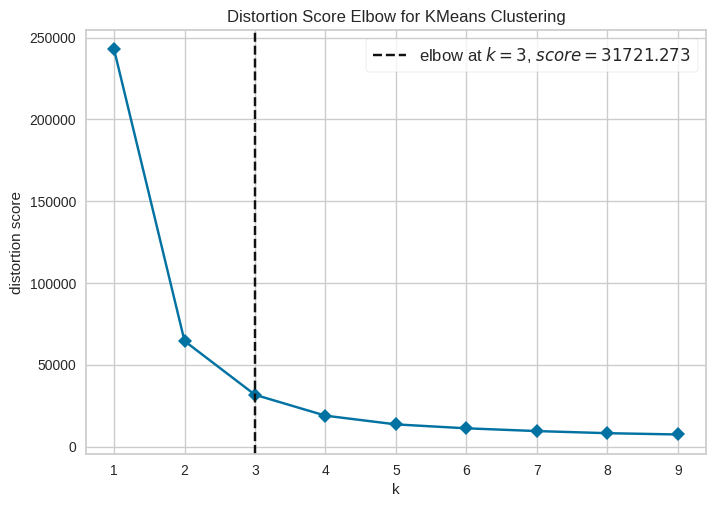

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Melakukan visualisasi Elbow Method menggunakan KElbowVisualizer()
X = df_cleaned.select_dtypes(include='number')
model = KMeans(random_state=42)
visualizer = KElbowVisualizer(model, k=(1, 10), metric='distortion', timings=False)
visualizer.fit(X)
visualizer.show()

In [ ]:
# Menggunakan algoritma K-Means Clustering
kmeans=KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)
df_cleaned['Cluster']=kmeans.labels_

Jalankan cell code ini untuk menyimpan model kamu.

In [ ]:
# # Menyimpan model menggunakan joblib
import joblib
joblib.dump(kmeans, "model_clustering.h5")

['model_clustering.h5']

(Opsional) Membangun Model Clustering [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [ ]:
# Menghitung dan menampilkan nilai Silhouette Score.
from sklearn.metrics import silhouette_score
score = silhouette_score(X, kmeans.labels_)
print(f"Silhouette Score: {score:.4f}")


Silhouette Score: 0.5376


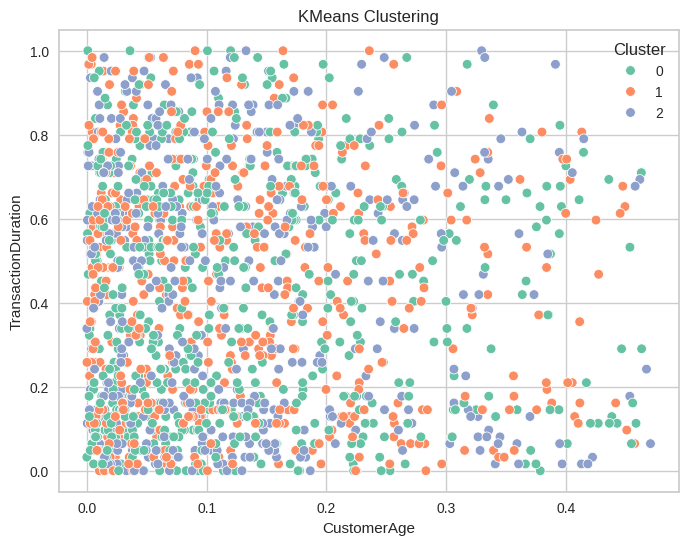

In [ ]:
# Membuat visualisasi hasil clustering
plt.figure(figsize=(8,6))
sns.scatterplot(x=X.iloc[:,0], y=X.iloc[:,1], hue=df_cleaned['Cluster'], palette='Set2')
plt.title("KMeans Clustering")
plt.xlabel(X.columns[1])
plt.ylabel(X.columns[2])
plt.legend(title='Cluster')
plt.show()


(Opsional) Membangun Model Clustering [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [ ]:
# Membangun model menggunakan PCA.
df_numeric=df_cleaned.select_dtypes(include=['number'])
pca=PCA(n_components=2)
pca_data= pca.fit_transform(df_numeric)
# Menyimpan data PCA sebagai Dataframe dengan nama PCA_<numbers>
PCA_2= pd.DataFrame(pca_data, columns=['PCA1', 'PCA2'])
# Pastikan kamu membangun model Kmeans baru dengan data yang sudah dimodifikasi melalui PCA.
kmeans2= KMeans(n_clusters=3)
kmeans2.fit(PCA_2)


KMeans(n_clusters=3)

In [ ]:
# Simpan model PCA sebagai perbandingan dengan menjalankan cell code ini joblib.dump(model,"PCA_model_clustering.h5")
# Pastikan yang disimpan model yang sudah melalui .fit berdasarkan dataset yang sudah dilakukan PCA
joblib.dump(kmeans2, "PCA_model_clustering.h5")

['PCA_model_clustering.h5']

# **5. Interpretasi Cluster**

## **a. Interpretasi Hasil Clustering**
1. **Contoh Interpretasi:**
- **Cluster 1: (Nasabah Bertransaksi dan Pendapatan Besar)**:
  - **Rata-rata (mean) Annual Income:** 0.953 (48,260)
  - **Rata-rata (mean) Spending Score:** 0.8 (56.48)
  - **Analisis:** Cluster ini mencakup pelanggan dengan pendapatan tahunan tinggi dan tingkat pengeluaran yang cukup tinggi. Pelanggan dalam cluster ini cenderung memiliki daya beli yang tinggi dan mereka lebih cenderung untuk membelanjakan sebagian besar pendapatan mereka. Sehingga rekomendasi pada kelompok nasabah ini adalah dengan menawarkan produk-produk investasi atau perbankan yang berkualitas tinggi.


In [ ]:
# Menampilkan analisis deskriptif minimal mean, min dan max untuk fitur numerik.
# Silakan menambahkan fungsi agregasi lainnya untuk experience lebih baik.
# pastikan output menghasilkan agregasi dan groupby bersamaan dengan mean, min, dan max.
num_cols=df_cleaned.select_dtypes(include=["number"]).columns
cluster_stats=df_cleaned.groupby("Cluster")[num_cols].agg(["mean","min","max"])
pd.set_option("display.max_columns",None)
cluster_stats




TransactionAmount                     CustomerAge            \
                     mean       min       max        mean  min  max   
Cluster                                                               
0                0.130503  0.000000  0.463168    0.420642  0.0  1.0   
1                0.132285  0.000099  0.457331    0.426823  0.0  1.0   
2                0.128716  0.000031  0.470558    0.425596  0.0  1.0   

        TransactionDuration                     LoginAttempts            \
                       mean       min       max          mean  min  max   
Cluster                                                                   
0                  0.369247  0.003448  0.996552           0.0  0.0  0.0   
1                  0.382693  0.000000  0.996552           0.0  0.0  0.0   
2                  0.379573  0.000000  1.000000           0.0  0.0  0.0   

        AccountBalance                     TransactionType_enc          \
                  mean       min       max                mean min max   
Cluster                                                                  
0             0.342935  0.000064  1.000000                 1.0   1   1   
1             0.340239  0.000774  0.997633                 1.0   1   1   
2             0.315380  0.001125  0.968596                 1.0   1   1   

        Channel_enc         CustomerOccupation_enc         Location_enc      \
               mean min max                   mean min max         mean min   
Cluster                                                                       
0          0.899830   0   2               1.490662   0   3    34.504244  27   
1          0.870968   0   2               1.485769   0   3    19.419355  13   
2          0.915217   0   2               1.560870   0   3     6.084783   0   

            CustomerAge_bin_enc         LoginAttempts_bin_enc         Cluster  \
        max                mean min max                  mean min max    mean   
Cluster                                                                         
0        42            1.246180   0   2                   0.0   0   0     0.0   
1        26            1.185958   0   2                   0.0   0   0     1.0   
2        12            1.200000   0   2                   0.0   0   0     2.0   

                 
        min max  
Cluster          
0         0   0  
1         1   1  
2         2   2

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya.
1. **Cluster 0 (Nasabah relatif muda dan saldo tertinggi)**:
  - **Rata-rata (mean) Customer Age: 0.421**
  - **Rata-rata (mean) Channel: 0.90**
  - **Rata-rata (mean) Account Balance: 0.343** <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Cluster ini berisi nasabah dengan rata-rata usia paling muda dan rata-rata saldo tertinggi dibandingkan cluster lain. Layanan yang cocok ditawarkan bagi nasabah dalam cluster ini adalah layanan ekslusif atau prioritas.

  2. **Cluster 1 (Nasabah Usia Muda dengan Saldo Sedang)**:
  - **Rata-rata (mean) Customer Age: 0.427**
  - **Rata-rata (mean) Channel: 0.871**
  - **Rata-rata (mean) Account Balance: 0.340** <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Cluster ini memiliki karakteristik yang hampir mirip dengan cluster 0. Perbedaannya adalah nasabah yang terdapat dalam cluster ini memiliki rata-rata usia sedikit lebih tua dari cluster 0 dan memiliki nilai channel dan saldo yang sedikit lebih rendah. Layanan yang cocok untuk ditawarkan pada nasabah dalam cluster ini adalah promosi layanan multi-channel, karena rata-rata channel pada layanan ini masih sangat kecil dibandingkan cluster lain.

  3. **Cluster 2 (Nasabah berusia muda dengan saldo rendah)**:
  - **Rata-rata (mean) Customer Age: 0.426**
  - **Rata-rata (mean) Channel: 0.915**
  - **Rata-rata (mean) Account Balance: 0.315** <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Cluster ini memiliki usia yang hampir sama dengan nasabah yang berada pada cluster 1, namun pada cluster ini, umur nasabah sedikit lebih muda. Rata-rata channel yang terdapat pada cluster ini bernilai lebih tinggi jika dibandingkan dengan cluster lain, menunjukkan bahwa penggunaan channel dalam cluster ini sangat bervariasi. Namun, nasabah yang terdapat dalam cluster ini memiliki rerata saldo yang paling rendah dibandingkan cluster lain. Oleh sebab itu, layanan yang cocok diberikan untuk nasabah yang terdapat dalam cluster ini adalah edukasi keuangan.

# **6. Mengeksport Data**

1. Simpan nama kolom hasil clustering dengan nama `Target`.
2. Simpan hasilnya ke dalam file CSV menggunakan function `to_csv()`.

In [ ]:
# Pastikan nama kolom clustering sudah diubah menjadi Target
df_cleaned=df_cleaned.rename(columns={"Cluster":"Target"})
df_cleaned

,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc,CustomerAge_bin,CustomerAge_bin_enc,LoginAttempts_bin,LoginAttempts_bin_enc,Target
0,0.007207,2023-04-11 16:29:14,Debit,San Diego,ATM,0.838710,Doctor,0.244828,0.0,0.336832,2024-11-04 8:08:08,1,0,0,36,Old,1,Low,0,0
1,0.195940,2023-06-27 16:44:19,Debit,Houston,ATM,0.806452,Doctor,0.451724,0.0,0.918055,2024-11-04 8:09:35,1,0,0,15,Old,1,Low,0,1
2,0.065680,2023-07-10 18:16:08,Debit,Mesa,Online,0.016129,Student,0.158621,0.0,0.068637,2024-11-04 8:07:04,1,2,3,23,Young,2,Low,0,1
3,0.096016,2023-05-05 16:32:11,Debit,Raleigh,Online,0.129032,Student,0.051724,0.0,0.569198,2024-11-04 8:09:06,1,2,3,33,Young,2,Low,0,0
4,0.047888,2023-04-03 17:15:01,Debit,Oklahoma City,ATM,0.000000,Student,0.558621,0.0,0.045738,2024-11-04 8:06:36,1,0,3,28,Young,2,Low,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1571,0.130953,2023-03-22 17:36:48,Debit,Tucson,Branch,0.483871,Doctor,0.575862,0.0,0.010318,2024-11-04 8:11:42,1,1,0,40,Medium,0,Low,0,0
1572,0.014785,2023-08-21 17:08:50,Debit,San Diego,Branch,0.612903,Retired,0.468966,0.0,0.220590,2024-11-04 8:08:39,1,1,2,36,Medium,0,Low,0,0
1573,0.096782,2023-02-24 16:24:46,Debit,Denver,Online,0.080645,Student,0.031034,0.0,0.112636,2024-11-04 8:12:22,1,2,3,10,Young,2,Low,0,2
1574,0.006212,2023-04-20 18:50:39,Debit,New York,Branch,0.935484,Retired,0.231034,0.0,0.323188,2024-11-04 8:07:37,1,1,2,27,Old,1,Low,0,0


In [ ]:
# Simpan Data
# ___.to_csv('data_clustering.csv', index=False)
df_cleaned.to_csv('data_clustering.csv',index=False)

(Opsional) Interpretasi Hasil Clustering [Skilled]

**Biarkan kosong jika tidak menerapkan kriteria skilled**

In [ ]:
# inverse dataset ke rentang normal untuk numerikal
df_cleaned[numeric_cols] = scaler.inverse_transform(df_cleaned[numeric_cols])
# tampilkan dataset yang sudah di-inverse
df_cleaned.head()

,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc,CustomerAge_bin,CustomerAge_bin_enc,LoginAttempts_bin,LoginAttempts_bin_enc,Target
0,14.09,2023-04-11 16:29:14,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 8:08:08,1,0,0,36,Old,1,Low,0,0
1,376.24,2023-06-27 16:44:19,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 8:09:35,1,0,0,15,Old,1,Low,0,1
2,126.29,2023-07-10 18:16:08,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 8:07:04,1,2,3,23,Young,2,Low,0,1
3,184.50,2023-05-05 16:32:11,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 8:09:06,1,2,3,33,Young,2,Low,0,0
4,92.15,2023-04-03 17:15:01,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,2024-11-04 8:06:36,1,0,3,28,Young,2,Low,0,0


In [ ]:
# inverse dataset yang sudah diencode ke kategori aslinya.
# Lengkapi kode berikut jika ingin menerapkan kriteria ini (silakan hapus simbol pagar pada kode yang akan digunakan.)
for col in cat_cols:
    le = encoders[col]
    df_cleaned[col+"_decode"] = le.inverse_transform(df_cleaned[col+"_enc"].astype(int))
 #tampilkan dataset yang sudah di-inverse
df_cleaned.head()


,TransactionAmount,PreviousTransactionDate,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,TransactionDate,TransactionType_enc,Channel_enc,CustomerOccupation_enc,Location_enc,CustomerAge_bin,CustomerAge_bin_enc,LoginAttempts_bin,LoginAttempts_bin_enc,Target,TransactionType_decode,Channel_decode,CustomerOccupation_decode,Location_decode
0,14.09,2023-04-11 16:29:14,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,2024-11-04 8:08:08,1,0,0,36,Old,1,Low,0,0,Debit,ATM,Doctor,San Diego
1,376.24,2023-06-27 16:44:19,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,2024-11-04 8:09:35,1,0,0,15,Old,1,Low,0,1,Debit,ATM,Doctor,Houston
2,126.29,2023-07-10 18:16:08,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,2024-11-04 8:07:04,1,2,3,23,Young,2,Low,0,1,Debit,Online,Student,Mesa
3,184.50,2023-05-05 16:32:11,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,2024-11-04 8:09:06,1,2,3,33,Young,2,Low,0,0,Debit,Online,Student,Raleigh
4,92.15,2023-04-03 17:15:01,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,2024-11-04 8:06:36,1,0,3,28,Young,2,Low,0,0,Debit,ATM,Student,Oklahoma City


In [ ]:
# Lakukan analisis deskriptif minimal mean, min dan max untuk fitur numerik dan mode untuk kategorikal seperti pada basic tetapi menggunakan data yang sudah diinverse.
# pastikan output menghasilkan agregasi dan groupby bersamaan dengan mean, min, dan max kembali setelah melakukan inverse
numeric_cols=['TransactionAmount','TransactionDuration','LoginAttempts','AccountBalance','CustomerAge']
cat_cols=["TransactionType","Channel","CustomerOccupation","Location"]

agg_dict={col:['mean','min','max']for col in numeric_cols}
agg_dict.update({col: (lambda x: x.mode().iloc[0] if not x.mode().empty else None) for col in cat_cols})
df_summary=df_cleaned.groupby('Target').agg(agg_dict)
df_summary=df_summary.reset_index()
df_summary


Target TransactionAmount               TransactionDuration               \
                      mean   min     max                mean   min    max   
0      0        250.676503  0.26  889.01          117.081494  11.0  299.0   
1      1        254.095769  0.45  877.81          120.981025  10.0  299.0   
2      2        247.247283  0.32  903.19          120.076087  10.0  300.0   

  LoginAttempts           AccountBalance                   CustomerAge        \
           mean  min  max           mean     min       max        mean   min   
0           1.0  1.0  1.0    5203.011273  102.20  14977.99   44.079796  18.0   
1           1.0  1.0  1.0    5162.902505  112.76  14942.78   44.462998  18.0   
2           1.0  1.0  1.0    4793.069522  117.98  14510.80   44.386957  18.0   

        TransactionType  Channel CustomerOccupation   Location  
    max        <lambda> <lambda>           <lambda>   <lambda>  
0  80.0           Debit      ATM            Student     Tucson  
1  80.0           Debit      ATM            Student       Mesa  
2  80.0           Debit      ATM            Student  Charlotte

## Menjelaskan karakteristik tiap cluster berdasarkan rentangnya setelah inverse.
1. **Cluster 0: (Nasabah Debit Pelajar di Tucson)**:
  - **Rata-rata (mean) Transaction Amount:250.68**
  - **Rata-rata (mean) Transaction Duration:117.1**
  - **Rata-rata (mean) Customer Age :44.1**
  - **Rata-rata (mean) Account Balance: 5203**
  - **Modus Pekerjaan :Student**
  - **Modus Lokasi: Tucson** <Sebelum inverse> <Setelah inverse>
  - **Analisis:** Nasabah pada cluster ini memiliki rerata jumlah transaksi yang standar dan durasi transaksi yang paling singkat dibandingkan dengan cluster lain. Rata-rata usia nasabah pada cluster ini juga sedikit lebih muda dibandingkan dengan cluster lain. Pekerjaan dan Lokasi dari nasabah pada cluster ini mayoritas merupakan pelajar dan dari Tucson yang memiliki saldo rata-rata yang cukup besar.

  2. **Cluster 1: (Nasabah Debit Pelajar di Mesa)**:
   - **Rata-rata (mean) Transaction Amount:254.1**
  - **Rata-rata (mean) Transaction Duration:121.0**
  - **Rata-rata (mean) Customer Age :44.45**
  - **Rata-rata (mean) Account Balance: 4793.1**
  - **Rata-rata (mean) Account Balance: 5162.9**
  - **Modus Pekerjaan : Student**
  - **Modus Lokasi: Mesa**<Sebelum inverse> <Setelah inverse>
  - **Analisis:** Nasabah pada cluster ini berusia paling tua dan memiliki jumlah transaksi paling besar serta berdurasi transaksi paling lama dibandingkan dengan cluster lain. Pekerjaan dan lokasi dari nasabah pada cluster ini mayoritas merupakan pelajar dan dari Mesa.

  
  3. **Cluster 2: (Nasabah Pelajar di Charlotte)**:
   - **Rata-rata (mean) Transaction Amount:247.25**
  - **Rata-rata (mean) Transaction Duration:120.07**
  - **Rata-rata (mean) Customer Age :44.39**
  - **Modus Pekerjaan :Student**
  - **Modus Lokasi :Charlotte**<Sebelum inverse> <Setelah inverse>
  - **Analisis:** Nasabah pada cluster ini mayoritas memiliki pekerjaan sebagai pelajar dan berlokasi di Charlotte. Rata-rata jumlah transaksi dan saldo pada cluster ini merupakan yang paling rendah jika dibandingkan dengan cluster lain.


(Opsional) Interpretasi Hasil Clustering [Advanced]

**Biarkan kosong jika tidak menerapkan kriteria advanced**

In [ ]:
# Mengintegrasikan kembali data yang telah di-inverse dengan hasil cluster.
df_inverse=df_cleaned.copy()

In [ ]:
# Simpan Data
df_inverse.to_csv('data_clustering_inverse.csv', index=False)

End of Code.